It is B2C Demand Forecasting:

In [123]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

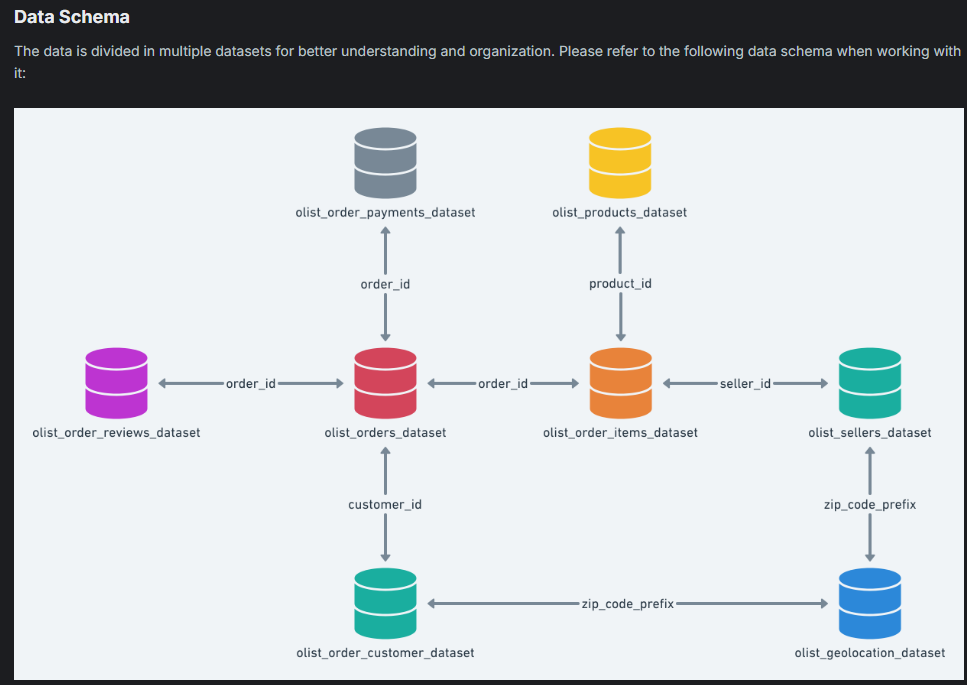

In [124]:
customer=pd.read_csv('../data/raw/olist_customers_dataset.csv')
geolocation=pd.read_csv('../data/raw/olist_geolocation_dataset.csv')
order_items=pd.read_csv('../data/raw/olist_order_items_dataset.csv')
order_payments=pd.read_csv('../data/raw/olist_order_payments_dataset.csv')
order_reviews=pd.read_csv('../data/raw/olist_order_reviews_dataset.csv')
orders=pd.read_csv('../data/raw/olist_orders_dataset.csv')
products=pd.read_csv('../data/raw/olist_products_dataset.csv')
sellers=pd.read_csv('../data/raw/olist_sellers_dataset.csv')
product_translaton=pd.read_csv('../data/raw/product_category_name_translation.csv')


In [125]:
l=[customer,geolocation,order_items,order_payments,order_reviews,orders,products,sellers,product_translaton]
for i in l:
  print(i.shape)

(99441, 5)
(1000163, 5)
(112650, 7)
(103886, 5)
(99224, 7)
(99441, 8)
(32951, 9)
(3095, 4)
(71, 2)


In [126]:
for df in l:
    print(df.columns)

Index(['customer_id', 'customer_unique_id', 'customer_zip_code_prefix',
       'customer_city', 'customer_state'],
      dtype='str')
Index(['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng',
       'geolocation_city', 'geolocation_state'],
      dtype='str')
Index(['order_id', 'order_item_id', 'product_id', 'seller_id',
       'shipping_limit_date', 'price', 'freight_value'],
      dtype='str')
Index(['order_id', 'payment_sequential', 'payment_type',
       'payment_installments', 'payment_value'],
      dtype='str')
Index(['review_id', 'order_id', 'review_score', 'review_comment_title',
       'review_comment_message', 'review_creation_date',
       'review_answer_timestamp'],
      dtype='str')
Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date'],
      dtype='str')
Index(['product_id', 'product_category_name'

In [127]:
customer.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [128]:
geolocation.head()

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


In [129]:
order_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [130]:
order_payments.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [131]:
order_reviews.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [132]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [133]:
sellers.head()

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


In [134]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB


In [135]:
orders['order_purchase_timestamp']=pd.to_datetime(orders['order_purchase_timestamp'])

In [136]:
products.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [137]:
products['product_category_name'].isna().sum()

np.int64(610)

In [138]:
sellers.head()

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


In [139]:
product_translaton.head()

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


In [140]:
product_translaton.nunique()

product_category_name            71
product_category_name_english    71
dtype: int64

In [141]:
products['product_category_name'].nunique()

73

In [142]:
products.isna().sum()

product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

In [143]:
product_translaton.isna().sum()

product_category_name            0
product_category_name_english    0
dtype: int64

In [144]:
prod_cat = set(products['product_category_name'].dropna().unique())
trans_cats = set(product_translaton['product_category_name'].unique())
prod_cat-trans_cats

{'pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos'}

In [145]:

new_translations = pd.DataFrame({
    'product_category_name': ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos'],
    'product_category_name_english': ['pc_gamer', 'kitchen_and_food_preparation_portables']
})
product_translaton = pd.concat([product_translaton, new_translations], ignore_index=True)

In [147]:
product_translaton.nunique()

product_category_name            73
product_category_name_english    73
dtype: int64

In [148]:
master_df=pd.merge(orders,order_items,on='order_id',how='inner')

In [149]:
master_df=pd.merge(master_df,products,on='product_id',how='left')

In [150]:
master_df=pd.merge(master_df,product_translaton,on='product_category_name',how='left')

In [151]:
master_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,...,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,1,87285b34884572647811a353c7ac498a,...,8.72,utilidades_domesticas,40.0,268.0,4.0,500.0,19.0,8.0,13.0,housewares
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,1,595fac2a385ac33a80bd5114aec74eb8,...,22.76,perfumaria,29.0,178.0,1.0,400.0,19.0,13.0,19.0,perfumery
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,1,aa4383b373c6aca5d8797843e5594415,...,19.22,automotivo,46.0,232.0,1.0,420.0,24.0,19.0,21.0,auto
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,1,d0b61bfb1de832b15ba9d266ca96e5b0,...,27.20,pet_shop,59.0,468.0,3.0,450.0,30.0,10.0,20.0,pet_shop
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,1,65266b2da20d04dbe00c5c2d3bb7859e,...,8.72,papelaria,38.0,316.0,4.0,250.0,51.0,15.0,15.0,stationery


In [152]:
master_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 23 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   order_id                       112650 non-null  str           
 1   customer_id                    112650 non-null  str           
 2   order_status                   112650 non-null  str           
 3   order_purchase_timestamp       112650 non-null  datetime64[us]
 4   order_approved_at              112635 non-null  str           
 5   order_delivered_carrier_date   111456 non-null  str           
 6   order_delivered_customer_date  110196 non-null  str           
 7   order_estimated_delivery_date  112650 non-null  str           
 8   order_item_id                  112650 non-null  int64         
 9   product_id                     112650 non-null  str           
 10  seller_id                      112650 non-null  str           
 11  shipping_li

In [153]:
master_df.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date',
       'price', 'freight_value', 'product_category_name',
       'product_name_lenght', 'product_description_lenght',
       'product_photos_qty', 'product_weight_g', 'product_length_cm',
       'product_height_cm', 'product_width_cm',
       'product_category_name_english'],
      dtype='str')

In [155]:
master_df.isna().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                  15
order_delivered_carrier_date     1194
order_delivered_customer_date    2454
order_estimated_delivery_date       0
order_item_id                       0
product_id                          0
seller_id                           0
shipping_limit_date                 0
price                               0
freight_value                       0
product_category_name            1603
product_name_lenght              1603
product_description_lenght       1603
product_photos_qty               1603
product_weight_g                   18
product_length_cm                  18
product_height_cm                  18
product_width_cm                   18
product_category_name_english    1603
dtype: int64

In [172]:
master_df = master_df.dropna(subset=['product_category_name_english'])

In [156]:
master_df['freight_value'].value_counts()

freight_value
15.10     3707
7.78      2262
14.10     1875
11.85     1846
18.23     1575
          ... 
6.81         1
46.95        1
173.23       1
5.01         1
0.80         1
Name: count, Length: 6999, dtype: int64

In [157]:
master_df.shape

(112650, 23)

In [158]:
cols_to_drop = [
    'order_approved_at', 'order_delivered_carrier_date',
    'order_delivered_customer_date', 'order_estimated_delivery_date',
    'seller_id', 'shipping_limit_date', 'product_category_name',
    'product_name_lenght', 'product_description_lenght', 'product_photos_qty',
    'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm'
]
master_df.drop(columns=cols_to_drop, inplace=True)

In [159]:
100- ((110197*100)/112650)

2.1775410563692787

In [160]:
master_df.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_item_id', 'product_id', 'price', 'freight_value',
       'product_category_name_english'],
      dtype='str')

In [161]:
master_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 9 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   order_id                       112650 non-null  str           
 1   customer_id                    112650 non-null  str           
 2   order_status                   112650 non-null  str           
 3   order_purchase_timestamp       112650 non-null  datetime64[us]
 4   order_item_id                  112650 non-null  int64         
 5   product_id                     112650 non-null  str           
 6   price                          112650 non-null  float64       
 7   freight_value                  112650 non-null  float64       
 8   product_category_name_english  111047 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), str(5)
memory usage: 7.7 MB


In [162]:
print(master_df['order_status'].value_counts())

order_status
delivered      110197
shipped          1185
canceled          542
invoiced          359
processing        357
unavailable         7
approved            3
Name: count, dtype: int64


In [163]:
master_df=master_df[master_df['order_status']=='delivered']

In [164]:
master_df.drop(columns=['order_item_id'], inplace=True)

In [165]:
master_df.drop(columns=['order_status'],inplace=True)

In [166]:
(110197*100 )/112650

97.82245894363072

In [167]:
master_df.shape

(110197, 7)

In [168]:
master_df['price'].max()

np.float64(6735.0)

In [169]:
master_df['freight_value'].max()

np.float64(409.68)

In [173]:
master_df.duplicated().sum()

np.int64(9865)

In [174]:
# Look at the duplicated rows, keeping all copies so you can compare them
duplicates = master_df[master_df.duplicated(keep=False)]
duplicates.sort_values(by='order_id').head(10)

,order_id,customer_id,order_purchase_timestamp,product_id,price,freight_value,product_category_name_english
61068,0008288aa423d2a3f00fcb17cd7d8719,2355af7c75e7c98b43a87b2a7f210dc5,2018-02-13 22:10:21,368c6c730842d78016ad823897a372db,49.90,13.37,garden_tools
61067,0008288aa423d2a3f00fcb17cd7d8719,2355af7c75e7c98b43a87b2a7f210dc5,2018-02-13 22:10:21,368c6c730842d78016ad823897a372db,49.90,13.37,garden_tools
41054,00143d0f86d6fbd9f9b38ab440ac16f5,2e45292979b9b2700ea09560eeb0f803,2017-10-16 15:29:43,e95ee6822b66ac6058e2e4aff656071a,21.33,15.10,sports_leisure
41055,00143d0f86d6fbd9f9b38ab440ac16f5,2e45292979b9b2700ea09560eeb0f803,2017-10-16 15:29:43,e95ee6822b66ac6058e2e4aff656071a,21.33,15.10,sports_leisure
41056,00143d0f86d6fbd9f9b38ab440ac16f5,2e45292979b9b2700ea09560eeb0f803,2017-10-16 15:29:43,e95ee6822b66ac6058e2e4aff656071a,21.33,15.10,sports_leisure
30529,001ab0a7578dd66cd4b0a71f5b6e1e41,8bb3bef4e75a95524235cdc11a7331af,2017-12-27 00:38:47,0b0172eb0fd18479d29c3bc122c058c2,24.89,17.63,electronics
30531,001ab0a7578dd66cd4b0a71f5b6e1e41,8bb3bef4e75a95524235cdc11a7331af,2017-12-27 00:38:47,0b0172eb0fd18479d29c3bc122c058c2,24.89,17.63,electronics
30530,001ab0a7578dd66cd4b0a71f5b6e1e41,8bb3bef4e75a95524235cdc11a7331af,2017-12-27 00:38:47,0b0172eb0fd18479d29c3bc122c058c2,24.89,17.63,electronics
47775,001d8f0e34a38c37f7dba2a37d4eba8b,d987da9fb4086ab7c2c0f83963cd6722,2017-05-14 17:19:44,e67307ff0f15ade43fcb6e670be7a74c,18.99,7.78,health_beauty
47774,001d8f0e34a38c37f7dba2a37d4eba8b,d987da9fb4086ab7c2c0f83963cd6722,2017-05-14 17:19:44,e67307ff0f15ade43fcb6e670be7a74c,18.99,7.78,health_beauty


In [175]:
master_df = master_df.groupby(master_df.columns.tolist(), dropna=False).size().reset_index(name='quantity')

In [176]:
master_df.shape

(98795, 8)

In [177]:
master_df.isna().sum()

order_id                         0
customer_id                      0
order_purchase_timestamp         0
product_id                       0
price                            0
freight_value                    0
product_category_name_english    0
quantity                         0
dtype: int64

In [178]:
master_df['quantity'].value_counts()

quantity
1     91941
2      5212
3       923
4       376
6       164
5       156
10        5
7         4
8         2
20        2
12        2
15        2
14        2
9         2
13        1
11        1
Name: count, dtype: int64

In [46]:
master_df.shape

(110197, 7)

In [179]:
master_df['order_id']=master_df['order_id'].str.strip().str.lower()
master_df['customer_id']=master_df['customer_id'].str.strip().str.lower()
master_df['product_id']=master_df['product_id'].str.strip().str.lower()
master_df['product_category_name_english']=master_df['product_category_name_english'].str.strip().str.lower()

In [180]:
master_df = master_df.astype({
    'price': 'float32',
    'freight_value': 'float32'
})

In [181]:
print(type(master_df['order_purchase_timestamp'].iloc[0]))


<class 'pandas.Timestamp'>


In [182]:
print(master_df['order_purchase_timestamp'].head())

0   2017-09-13 08:59:02
1   2017-04-26 10:53:06
2   2018-01-14 14:33:31
3   2018-08-08 10:00:35
4   2017-02-04 13:57:51
Name: order_purchase_timestamp, dtype: datetime64[us]


In [ ]:
master_df.info()

In [184]:
for cols in master_df:
  print(master_df[cols].is_unique)

False
False
False
False
False
False
False
False


In [186]:
master_df['order_date'] = master_df['order_purchase_timestamp'].dt.normalize()

In [187]:
master_df.head()

,order_id,customer_id,order_purchase_timestamp,product_id,price,freight_value,product_category_name_english,quantity,order_date
0,00010242fe8c5a6d1ba2dd792cb16214,3ce436f183e68e07877b285a838db11a,2017-09-13 08:59:02,4244733e06e7ecb4970a6e2683c13e61,58.900002,13.290000,cool_stuff,1,2017-09-13
1,00018f77f2f0320c557190d7a144bdd3,f6dd3ec061db4e3987629fe6b26e5cce,2017-04-26 10:53:06,e5f2d52b802189ee658865ca93d83a8f,239.899994,19.930000,pet_shop,1,2017-04-26
2,000229ec398224ef6ca0657da4fc703e,6489ae5e4333f3693df5ad4372dab6d3,2018-01-14 14:33:31,c777355d18b72b67abbeef9df44fd0fd,199.000000,17.870001,furniture_decor,1,2018-01-14
3,00024acbcdf0a6daa1e931b038114c75,d4eb9395c8c0431ee92fce09860c5a06,2018-08-08 10:00:35,7634da152a4610f1595efa32f14722fc,12.990000,12.790000,perfumery,1,2018-08-08
4,00042b26cf59d7ce69dfabb4e55b4fd9,58dbd0b2d70206bf40e62cd34e84d795,2017-02-04 13:57:51,ac6c3623068f30de03045865e4e10089,199.899994,18.139999,garden_tools,1,2017-02-04


In [188]:
master_df.isna().sum()

order_id                         0
customer_id                      0
order_purchase_timestamp         0
product_id                       0
price                            0
freight_value                    0
product_category_name_english    0
quantity                         0
order_date                       0
dtype: int64

In [189]:
master_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 98795 entries, 0 to 98794
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       98795 non-null  str           
 1   customer_id                    98795 non-null  str           
 2   order_purchase_timestamp       98795 non-null  datetime64[us]
 3   product_id                     98795 non-null  str           
 4   price                          98795 non-null  float32       
 5   freight_value                  98795 non-null  float32       
 6   product_category_name_english  98795 non-null  str           
 7   quantity                       98795 non-null  int64         
 8   order_date                     98795 non-null  datetime64[us]
dtypes: datetime64[us](2), float32(2), int64(1), str(4)
memory usage: 6.0 MB


In [195]:
master_df.to_csv('../data/processed/olist_cleaned_silver_spine.csv',index=False)